# Extended Data Figure 6: Discrete depth landscape

Run from this notebook directory. Color shows mean realized cooperation across initial strategy compositions; dotted cells show strict local protection of pure DISC against rare ALLD and ALLC. Both depths are integers. The supplied external table is loaded by default.

## Configuration

Set `RECOMPUTE=True` only for an explicit full 256-condition scan. This can be expensive.

In [1]:
from __future__ import annotations
from pathlib import Path
from dataclasses import dataclass, replace
from typing import Dict, Mapping, Sequence, Tuple
import json

import numpy as np
import pandas as pd
from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'extended_data_figure6'
FIGURES = ROOT / 'figures' / 'extended_data_figure6'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

NORM_ORDER = ('SC', 'SH', 'SJ', 'SS')
NORM_PARAMETERS = {'SC': (1., 0.), 'SH': (0., 0.), 'SJ': (0., 1.), 'SS': (1., 1.)}
NORM_NAMES = {'SC': 'Scoring', 'SH': 'Shunning', 'SJ': 'Stern Judging', 'SS': 'Simple Standing'}
B_OVER_C = 5.0
E1 = E2 = 0.02
SEED = 2026
DEPTH_VALUES = tuple(range(8))
SETTINGS = dict(mesh_resolution=23, n_initial=512, chunk_steps=4000,
                max_chunks=64, stable_checks=2, mean_tolerance=2e-5)
MODEL = dict(b_over_c=B_OVER_C, e1=E1, e2=E2, alpha=1., beta=1.)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.linewidth': .7, 'xtick.direction': 'out',
                     'ytick.direction': 'out', 'hatch.linewidth': .45,
                     'pdf.fonttype': 42, 'svg.fonttype': 'none'})

## Model and calculation

The source all-good reputation ODE, interpolated replicator field, midpoint strategy integration, and repeated-mean convergence gate are retained. The historical shifted-Halton fallback sampler is made explicit; its analytic Scoring baseline matches the supplied record exactly. Historical Delaunay triangulation details remain unidentified. Regeneration allows 64 chunks rather than the historical eight. Passing the mean gate does not require every strategy residual to vanish.

In [2]:
@dataclass(frozen=True)
class ModelParameters:
    norm: str = 'SS'
    b: float = 5.0
    c: float = 1.0
    e1: float = 0.02
    e2: float = 0.02
    alpha: float = 1.0
    beta: float = 1.0
    k1: int = 1
    k2: int = 1

    @property
    def p(self) -> float:
        return NORM_PARAMETERS[self.norm][0]

    @property
    def q(self) -> float:
        return NORM_PARAMETERS[self.norm][1]

    def validated(self) -> 'ModelParameters':
        if self.norm not in NORM_PARAMETERS:
            raise ValueError(f'Unknown norm {self.norm!r}; use {NORM_ORDER}.')
        if not self.b > self.c > 0.0:
            raise ValueError('Require b > c > 0.')
        if not (0.0 <= self.e1 < 0.5 and 0.0 <= self.e2 < 0.5):
            raise ValueError('Require 0 <= e1,e2 < 1/2.')
        if not (0.0 <= self.alpha <= 1.0 and 0.0 <= self.beta <= 1.0):
            raise ValueError('Require 0 <= alpha,beta <= 1.')
        if not isinstance(self.k1, (int, np.integer)) or not isinstance(self.k2, (int, np.integer)) or self.k1 < 0 or (self.k2 < 0):
            raise ValueError('Require non-negative integer depths k1 and k2.')
        return self

    def with_updates(self, **changes: float | str) -> 'ModelParameters':
        return replace(self, **changes).validated()

@dataclass
class ReputationSolution:
    reputations: np.ndarray
    converged: np.ndarray
    residual: np.ndarray
    steps: int

@dataclass
class StrategyInterpolator:
    parameters: ModelParameters
    mesh_frequencies: np.ndarray
    mesh_reputations: np.ndarray
    mesh_rhs: np.ndarray
    mesh_cooperation: np.ndarray
    mesh_max_reputation_residual: float
    dx: LinearNDInterpolator
    dy: LinearNDInterpolator
    dx_nearest: NearestNDInterpolator
    dy_nearest: NearestNDInterpolator

    def evaluate(self, frequencies: np.ndarray) -> np.ndarray:
        f = normalize_frequencies(frequencies)
        xy = f[:, :2]
        dx = np.asarray(self.dx(xy), dtype=float).reshape(-1)
        dy = np.asarray(self.dy(xy), dtype=float).reshape(-1)
        missing = ~np.isfinite(dx) | ~np.isfinite(dy)
        if np.any(missing):
            dx[missing] = np.asarray(self.dx_nearest(xy[missing])).reshape(-1)
            dy[missing] = np.asarray(self.dy_nearest(xy[missing])).reshape(-1)
        dz = -dx - dy
        rhs = np.column_stack((dx, dy, dz))
        rhs[f <= 1e-12] = 0.0
        rhs -= f * rhs.sum(axis=1, keepdims=True)
        return rhs

def as_2d(array: np.ndarray | Sequence[float], width: int=3) -> np.ndarray:
    result = np.asarray(array, dtype=float)
    if result.ndim == 1:
        result = result[None, :]
    if result.ndim != 2 or result.shape[1] != width:
        raise ValueError(f'Expected an array with shape (n,{width}).')
    return result

def normalize_frequencies(frequencies: np.ndarray | Sequence[float]) -> np.ndarray:
    f = as_2d(frequencies).copy()
    f = np.maximum(f, 0.0)
    totals = f.sum(axis=1, keepdims=True)
    bad = totals[:, 0] <= 0.0
    if np.any(bad):
        f[bad] = np.array([0.0, 1.0, 0.0])
        totals = f.sum(axis=1, keepdims=True)
    return f / totals

def effective_assessment_probabilities(parameters: ModelParameters) -> Tuple[float, float, float, float]:
    par = parameters.validated()
    epsilon = (1.0 - par.e1) * (1.0 - par.e2) + par.e1 * par.e2
    p_cg = epsilon
    p_cb = par.p * (epsilon - par.e2) + par.q * (1.0 - epsilon - par.e2) + par.e2
    p_dg = par.e2
    p_db = par.q * (1.0 - 2.0 * par.e2) + par.e2
    return (p_cg, p_cb, p_dg, p_db)

def reputation_transform(phi: np.ndarray | float, alpha: float, beta: float, k1: int=1, k2: int=1) -> np.ndarray:
    if k1 < 0 or k2 < 0:
        raise ValueError('k1 and k2 must be non-negative.')
    phi_array = np.asarray(phi, dtype=float)
    one_minus = 1.0 - phi_array
    denominator = one_minus ** k1 + phi_array ** k2 - one_minus ** k1 * phi_array ** k2
    warning_readout = np.zeros_like(phi_array)
    for m in range(1, k1 + 1):
        warning_readout += (alpha * one_minus) ** m
    suspicious_readout = np.zeros_like(phi_array)
    for n in range(1, k2 + 1):
        suspicious_readout += phi_array ** n * (1.0 - beta ** n)
    numerator = phi_array ** (k2 + 1) * (1.0 + warning_readout) + one_minus ** (k1 + 1) * suspicious_readout
    return numerator / denominator

def positive_assessment_probabilities(reputations: np.ndarray, frequencies: np.ndarray, parameters: ModelParameters) -> np.ndarray:
    r = as_2d(reputations)
    f = normalize_frequencies(frequencies)
    if len(r) != len(f):
        if len(r) == 1:
            r = np.repeat(r, len(f), axis=0)
        elif len(f) == 1:
            f = np.repeat(f, len(r), axis=0)
        else:
            raise ValueError('Reputation and frequency batches must align.')
    p_cg, p_cb, p_dg, p_db = effective_assessment_probabilities(parameters)
    mean_good = np.sum(f * r, axis=1)
    agreement_good = np.sum(f * r ** 2, axis=1)
    disagreement_ordered = mean_good - agreement_good
    agreement_bad = 1.0 - 2.0 * mean_good + agreement_good
    phi_allc = mean_good * p_cg + (1.0 - mean_good) * p_cb
    phi_alld = mean_good * p_dg + (1.0 - mean_good) * p_db
    phi_disc = agreement_good * p_cg + disagreement_ordered * (p_cb + p_dg) + agreement_bad * p_db
    return np.column_stack((phi_allc, phi_alld, phi_disc))

def reputation_rhs(reputations: np.ndarray, frequencies: np.ndarray, parameters: ModelParameters) -> np.ndarray:
    r = as_2d(reputations)
    phi = positive_assessment_probabilities(r, frequencies, parameters)
    generated = reputation_transform(phi, parameters.alpha, parameters.beta, parameters.k1, parameters.k2)
    return generated - r

def solve_reputation_equilibrium(frequencies: np.ndarray | Sequence[float], parameters: ModelParameters, *, initial_reputations: np.ndarray | Sequence[float] | None=None, dt: float=0.1, tolerance: float=1e-10, max_steps: int=20000) -> ReputationSolution:
    par = parameters.validated()
    f = normalize_frequencies(frequencies)
    if initial_reputations is None:
        r = np.ones_like(f)
    else:
        r0 = as_2d(initial_reputations)
        if len(r0) == 1:
            r = np.repeat(r0, len(f), axis=0)
        elif len(r0) == len(f):
            r = r0.copy()
        else:
            raise ValueError('initial_reputations has an incompatible batch size.')
    r = np.clip(r, 0.0, 1.0)
    converged = np.zeros(len(f), dtype=bool)
    residual = np.full(len(f), np.inf)
    for step in range(1, max_steps + 1):
        k1 = reputation_rhs(r, f, par)
        residual = np.max(np.abs(k1), axis=1)
        converged = residual <= tolerance
        if np.all(converged):
            break
        active = ~converged
        k2 = reputation_rhs(np.clip(r + 0.5 * dt * k1, 0.0, 1.0), f, par)
        k3 = reputation_rhs(np.clip(r + 0.5 * dt * k2, 0.0, 1.0), f, par)
        k4 = reputation_rhs(np.clip(r + dt * k3, 0.0, 1.0), f, par)
        update = dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
        r[active] = np.clip(r[active] + update[active], 0.0, 1.0)
    else:
        step = max_steps
    residual = np.max(np.abs(reputation_rhs(r, f, par)), axis=1)
    converged = residual <= tolerance
    return ReputationSolution(r, converged, residual, step)

def solve_reputation_equilibrium_with_retry(frequencies: np.ndarray | Sequence[float], parameters: ModelParameters, *, tolerance: float=1e-09) -> ReputationSolution:
    f = normalize_frequencies(frequencies)
    first = solve_reputation_equilibrium(f, parameters, tolerance=tolerance)
    failed = ~first.converged
    if not np.any(failed):
        return first
    retry = solve_reputation_equilibrium(f[failed], parameters, initial_reputations=first.reputations[failed], dt=0.2, tolerance=tolerance, max_steps=80000)
    reputations = first.reputations.copy()
    residual = first.residual.copy()
    converged = first.converged.copy()
    reputations[failed] = retry.reputations
    residual[failed] = retry.residual
    converged[failed] = retry.converged
    return ReputationSolution(reputations=reputations, converged=converged, residual=residual, steps=first.steps + retry.steps)

def payoffs(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    r = as_2d(reputations)
    if len(r) == 1 and len(f) > 1:
        r = np.repeat(r, len(f), axis=0)
    if len(r) != len(f):
        raise ValueError('Reputation and frequency batches must align.')
    x = f[:, 0]
    z = f[:, 2]
    mean_good = np.sum(f * r, axis=1)
    common = 1.0 - parameters.e1
    pi_allc = common * (parameters.b * (x + z * r[:, 0]) - parameters.c)
    pi_alld = common * parameters.b * (x + z * r[:, 1])
    pi_disc = common * (parameters.b * (x + z * r[:, 2]) - parameters.c * mean_good)
    return np.column_stack((pi_allc, pi_alld, pi_disc))

def strategy_rhs_from_reputations(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    pi = payoffs(f, reputations, parameters)
    mean_payoff = np.sum(f * pi, axis=1, keepdims=True)
    rhs = f * (pi - mean_payoff)
    rhs -= f * rhs.sum(axis=1, keepdims=True)
    return rhs

def cooperation_rate(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float], parameters: ModelParameters) -> np.ndarray:
    return (1.0 - parameters.e1) * intended_cooperation_rate(frequencies, reputations)

def intended_cooperation_rate(frequencies: np.ndarray | Sequence[float], reputations: np.ndarray | Sequence[float]) -> np.ndarray:
    f = normalize_frequencies(frequencies)
    r = as_2d(reputations)
    if len(r) == 1 and len(f) > 1:
        r = np.repeat(r, len(f), axis=0)
    mean_good = np.sum(f * r, axis=1)
    return f[:, 0] + f[:, 2] * mean_good

def triangle_lattice(resolution: int, *, include_boundary: bool=True) -> np.ndarray:
    if resolution < 2:
        raise ValueError('resolution must be at least 2.')
    points = []
    for i in range(resolution + 1):
        for j in range(resolution + 1 - i):
            if not include_boundary and (i == 0 or j == 0 or i + j == resolution):
                continue
            x = i / resolution
            y = j / resolution
            points.append((x, y, 1.0 - x - y))
    return np.asarray(points, dtype=float)

def uniform_simplex_points(n, *, seed=2026):
    """Use the historical shifted-Halton fallback explicitly."""
    if n < 1:
        raise ValueError('n must be positive.')
    shift = np.random.RandomState(seed).random_sample(2)
    indices = np.arange(1, n + 1)
    coordinates = []
    for base in (2, 3):
        remaining = indices.copy()
        values = np.zeros(n, dtype=float)
        factor = 1.0 / base
        while np.any(remaining):
            values += factor * (remaining % base)
            remaining //= base
            factor /= base
        coordinates.append(values)
    uv = (np.column_stack(coordinates) + shift) % 1.0
    reflected = uv[:, 0] + uv[:, 1] > 1.0
    uv[reflected] = 1.0 - uv[reflected]
    return np.column_stack((uv[:, 0], uv[:, 1], 1.0 - uv.sum(axis=1)))

def build_strategy_interpolator(parameters: ModelParameters, *, mesh_resolution: int=25, reputation_tolerance: float=1e-10) -> StrategyInterpolator:
    f = triangle_lattice(mesh_resolution)
    reputation_solution = solve_reputation_equilibrium_with_retry(f, parameters, tolerance=reputation_tolerance)
    if not np.all(reputation_solution.converged):
        raise RuntimeError(f'Reputation mesh failed to converge; max residual {np.max(reputation_solution.residual):.3e}.')
    r = reputation_solution.reputations
    rhs = strategy_rhs_from_reputations(f, r, parameters)
    coop = cooperation_rate(f, r, parameters)
    xy = f[:, :2]
    return StrategyInterpolator(parameters=parameters, mesh_frequencies=f, mesh_reputations=r, mesh_rhs=rhs, mesh_cooperation=coop, mesh_max_reputation_residual=float(np.max(reputation_solution.residual)), dx=LinearNDInterpolator(xy, rhs[:, 0], fill_value=np.nan), dy=LinearNDInterpolator(xy, rhs[:, 1], fill_value=np.nan), dx_nearest=NearestNDInterpolator(xy, rhs[:, 0]), dy_nearest=NearestNDInterpolator(xy, rhs[:, 1]))

def integrate_strategy_batch(initial_frequencies: np.ndarray | Sequence[float], interpolator: StrategyInterpolator, *, dt: float=0.1, tolerance: float=2e-07, max_steps: int=8000) -> Tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    f = normalize_frequencies(initial_frequencies)
    converged = np.zeros(len(f), dtype=bool)
    residual = np.full(len(f), np.inf)
    for step in range(1, max_steps + 1):
        active_indices = np.flatnonzero(~converged)
        if len(active_indices) == 0:
            break
        active_f = f[active_indices]
        k1 = interpolator.evaluate(active_f)
        active_residual = np.max(np.abs(k1), axis=1)
        residual[active_indices] = active_residual
        newly_converged = active_residual <= tolerance
        converged[active_indices[newly_converged]] = True
        moving_indices = active_indices[~newly_converged]
        if len(moving_indices) == 0:
            continue
        moving_f = f[moving_indices]
        moving_k1 = k1[~newly_converged]
        midpoint = normalize_frequencies(moving_f + 0.5 * dt * moving_k1)
        k2 = interpolator.evaluate(midpoint)
        f[moving_indices] = normalize_frequencies(moving_f + dt * k2)
    else:
        step = max_steps
    residual = np.max(np.abs(interpolator.evaluate(f)), axis=1)
    converged = residual <= tolerance
    return (f, converged, residual, step)

def disc_ess_thresholds(parameters: ModelParameters) -> Dict[str, float | bool | np.ndarray]:
    f_disc = np.array([[0.0, 0.0, 1.0]])
    solution = solve_reputation_equilibrium(f_disc, parameters)
    if not solution.converged[0]:
        raise RuntimeError('All-DISC reputation equilibrium did not converge.')
    r_c, r_d, r_r = solution.reputations[0]
    if r_r <= r_d + 1e-12:
        lower = np.inf
    else:
        lower = r_r / (r_r - r_d)
    if r_c <= r_r + 1e-12:
        upper = np.inf
    else:
        upper = (1.0 - r_r) / (r_c - r_r)
    ratio = parameters.b / parameters.c
    lambda_alld = (1.0 - parameters.e1) * (parameters.b * r_d - (parameters.b - parameters.c) * r_r)
    lambda_allc = (1.0 - parameters.e1) * (parameters.b * r_c - parameters.c - (parameters.b - parameters.c) * r_r)
    return {'reputations': solution.reputations[0].copy(), 'critical_b_over_c_alld': float(lower), 'critical_b_over_c_allc': float(upper), 'actual_b_over_c': float(ratio), 'lambda_alld': float(lambda_alld), 'lambda_allc': float(lambda_allc), 'stable_against_alld': bool(lambda_alld < 0.0), 'stable_against_allc': bool(lambda_allc < 0.0), 'disc_is_ess_in_three_strategy_space': bool(lambda_alld < 0.0 and lambda_allc < 0.0)}

def is_sc_effective_no_inertia(parameters):
    return parameters.norm == 'SC' and (parameters.k1 == 0 and parameters.k2 == 0 or (parameters.alpha == 0.0 and parameters.beta == 0.0))

def sc_no_inertia_reputations(frequencies, parameters):
    f = normalize_frequencies(frequencies)
    epsilon = (1.0 - parameters.e1) * (1.0 - parameters.e2) + parameters.e1 * parameters.e2
    delta = epsilon - parameters.e2
    mean_good = (parameters.e2 + delta * f[:, 0]) / (1.0 - delta * f[:, 2])
    return np.column_stack((np.full(len(f), epsilon), np.full(len(f), parameters.e2), parameters.e2 + delta * mean_good))

def sc_no_inertia_rhs(frequencies, parameters):
    f = normalize_frequencies(frequencies)
    reputations = sc_no_inertia_reputations(f, parameters)
    return strategy_rhs_from_reputations(f, reputations, parameters)

def adaptive_global_statistics(parameters, settings, seed=SEED):
    exact_sc = is_sc_effective_no_inertia(parameters)
    interpolator = None if exact_sc else build_strategy_interpolator(parameters, mesh_resolution=settings['mesh_resolution'], reputation_tolerance=1e-09)
    final = uniform_simplex_points(settings['n_initial'], seed=seed)
    previous_mean = None
    stable_count = 0
    observable_stable = False
    total_steps = 0
    for _ in range(settings['max_chunks']):
        if exact_sc:
            for _step in range(settings['chunk_steps']):
                first = sc_no_inertia_rhs(final, parameters)
                midpoint = normalize_frequencies(final + 0.025 * first)
                second = sc_no_inertia_rhs(midpoint, parameters)
                final = normalize_frequencies(final + 0.05 * second)
            steps = settings['chunk_steps']
            reputations = sc_no_inertia_reputations(final, parameters)
        else:
            final, _, _, steps = integrate_strategy_batch(final, interpolator, dt=0.1, tolerance=1e-06, max_steps=settings['chunk_steps'])
            rep = solve_reputation_equilibrium_with_retry(final, parameters, tolerance=1e-09)
            if not np.all(rep.converged):
                raise RuntimeError('Final reputation solve failed.')
            reputations = rep.reputations
        total_steps += steps
        cooperation = cooperation_rate(final, reputations, parameters)
        current_mean = float(np.mean(cooperation))
        if previous_mean is not None:
            stable_now = abs(current_mean - previous_mean) <= settings['mean_tolerance']
            stable_count = stable_count + 1 if stable_now else 0
            if stable_count >= settings['stable_checks']:
                observable_stable = True
                break
        previous_mean = current_mean
    rhs = strategy_rhs_from_reputations(final, reputations, parameters)
    residual = np.max(np.abs(rhs), axis=1)
    cooperative = cooperation >= 0.5
    conditional = float(np.mean(cooperation[cooperative])) if np.any(cooperative) else np.nan
    theory = disc_ess_thresholds(parameters)
    return {'expected_cooperation': float(np.mean(cooperation)), 'cooperative_basin': float(np.mean(cooperative)), 'conditional_cooperation': conditional, 'observable_stable': int(observable_stable), 'residual_q99': float(np.quantile(residual, 0.99)), 'strategy_steps': int(total_steps), 'R_L': float(theory['critical_b_over_c_alld']), 'R_U': float(theory['critical_b_over_c_allc']), 'lambda_ALLD': float(theory['lambda_alld']), 'lambda_ALLC': float(theory['lambda_allc']), 'disc_locally_protected': int(theory['disc_is_ess_in_three_strategy_space'])}

probe = np.linspace(0., 1., 101)
np.testing.assert_allclose(reputation_transform(probe, alpha=0., beta=0., k1=0, k2=0), probe, rtol=0, atol=1e-14)
np.testing.assert_allclose(reputation_transform(probe, alpha=1., beta=1., k1=1, k2=1),
                          probe**2 * (2-probe) / (1-probe+probe**2), rtol=0, atol=1e-14)
reference = disc_ess_thresholds(ModelParameters(norm='SC'))
np.testing.assert_allclose(reference['reputations'],
                          [.9968690336, .0008078336, .9962790641], rtol=0, atol=2e-9)
print('Model identity and all-good resident checks passed.')


Model identity and all-good resident checks passed.


## External data

Three historically failed one-step conditions were recalculated to convergence in the current environment using the identified historical sampler. These are numerical reconstructions, not exact continuations of historical trajectories: the original interpolation environment is unknown. Original rows, prefix differences, and new values are retained separately. The other 253 rows are unchanged. Missing data never start a calculation automatically.

In [3]:
path = DATA / '24_k1_k2_publication.csv'
config_path = DATA / 'input_config.json'
if RECOMPUTE:
    rows = []
    for norm in NORM_ORDER:
        for k2 in DEPTH_VALUES:
            for k1 in DEPTH_VALUES:
                par = ModelParameters(norm=norm, b=B_OVER_C, c=1., e1=E1, e2=E2,
                                      alpha=1., beta=1., k1=k1, k2=k2)
                stats = adaptive_global_statistics(par, SETTINGS, seed=SEED)
                if not stats['observable_stable']:
                    raise RuntimeError(f'Unconverged cooperation: {norm}, k1={k1}, k2={k2}.')
                rows.append(dict(task_id=f'{norm}_k1_{k1:02d}_k2_{k2:02d}',
                                 norm=norm, alpha=1., beta=1., k1=k1, k2=k2,
                                 b_over_c=B_OVER_C, e1=E1, e2=E2,
                                 mesh_resolution=SETTINGS['mesh_resolution'],
                                 n_initial=SETTINGS['n_initial'], **stats))
                print(f'{norm} ({k1},{k2}): C={stats["expected_cooperation"]:.6f}', flush=True)
    pd.DataFrame(rows).to_csv(path, index=False)
    config_path.write_text(json.dumps(dict(model=MODEL, regeneration_settings=SETTINGS,
                         seed=SEED, depths=list(DEPTH_VALUES),
                         data_source='Explicit full regeneration'), indent=2)+'\n')

if not path.is_file() or not config_path.is_file():
    raise FileNotFoundError('Supply data/extended_data_figure6 or explicitly set RECOMPUTE=True.')
config = json.loads(config_path.read_text())
if config['model'] != MODEL:
    raise ValueError('Saved model settings do not match MODEL.')
data = pd.read_csv(path)
required = {'norm','k1','k2','alpha','beta','b_over_c','e1','e2','expected_cooperation',
            'lambda_ALLD','lambda_ALLC','disc_locally_protected','observable_stable'}
assert required.issubset(data.columns)
assert set(data.norm) == set(NORM_ORDER) and len(data) == 4*8**2
assert not data.duplicated(['norm','k1','k2']).any()
for norm, part in data.groupby('norm'):
    assert set(zip(part.k1, part.k2)) == {(i,j) for i in DEPTH_VALUES for j in DEPTH_VALUES}
for field, value in MODEL.items():
    assert np.allclose(data[field], value)
assert data.expected_cooperation.between(0,1).all()
assert data.observable_stable.eq(1).all(), 'Unconverged cooperation values cannot be exported.'
assert np.isfinite(data[['expected_cooperation','lambda_ALLD','lambda_ALLC']]).all().all()
expected_protection = (data.lambda_ALLD < 0) & (data.lambda_ALLC < 0)
np.testing.assert_array_equal(data.disc_locally_protected.astype(bool), expected_protection)

summary = data.groupby('norm', sort=False).agg(
    conditions=('expected_cooperation','size'),
    min_cooperation=('expected_cooperation','min'),
    max_cooperation=('expected_cooperation','max'),
    protected_cells=('disc_locally_protected','sum'),
    max_strategy_residual_q99=('residual_q99','max'))
summary.to_csv(DATA / 'grid_summary.csv')
print('Loaded 256 complete, observable-stable depth conditions.')

Loaded 256 complete, observable-stable depth conditions.


## Panels

The blue palette and dotted overlay follow the final source style. Axis labels, titles, a colorbar, and the legend are included directly. The overlay uses both raw invasion payoff advantages strictly below zero, independently of the cooperation value. There are no interpolated depth boundaries.

In [4]:
CMAP = LinearSegmentedColormap.from_list('cooperation_blue',
    ['#F4F8FB','#DCEAF3','#A9CFE3','#6FA8C9','#2F6F9F'])
HATCH_COLOR = (.1,.1,.1,.32)

def arrays(norm):
    part = data.loc[data.norm.eq(norm)]
    def grid(column):
        return part.pivot(index='k2', columns='k1', values=column).loc[list(DEPTH_VALUES),list(DEPTH_VALUES)].to_numpy()
    return grid('expected_cooperation'), grid('disc_locally_protected').astype(bool)

def draw_panel(ax, norm, panel=None):
    cooperation, protected = arrays(norm)
    edges = np.arange(-.5,8.,1.)
    image = ax.pcolormesh(edges, edges, cooperation, cmap=CMAP, vmin=0, vmax=1,
                         shading='flat', rasterized=True)
    for j,i in np.argwhere(protected):
        ax.add_patch(Rectangle((i-.5,j-.5),1,1,facecolor='none',
                               edgecolor=HATCH_COLOR,linewidth=0,hatch='....'))
    ax.set(xlim=(-.5,7.5),ylim=(-.5,7.5),xticks=DEPTH_VALUES,yticks=DEPTH_VALUES,
           xlabel=r'Tolerance depth $k_1$',ylabel=r'Strictness depth $k_2$',
           title=NORM_NAMES[norm],aspect='equal')
    ax.tick_params(length=2.5,pad=2)
    if panel:
        ax.text(-.16,1.04,panel,transform=ax.transAxes,fontweight='bold',fontsize=11)
    return image

def save_figure(fig, name):
    for extension in ('pdf','svg'):
        fig.savefig(FIGURES / f'{name}.{extension}', bbox_inches='tight', pad_inches=.04)

HATCH_LEGEND = Patch(facecolor='white',edgecolor='#777777',hatch='....',
                    label='Pure DISC resists rare ALLD and ALLC')

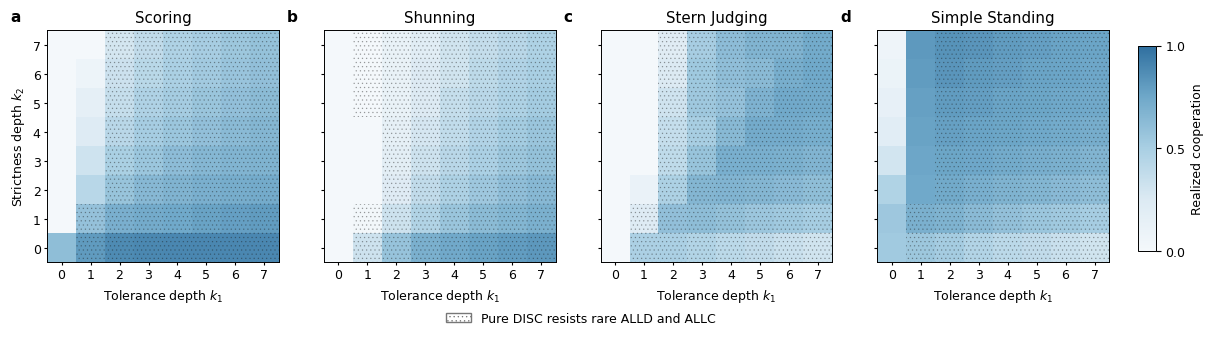

Saved four panels and one combined figure in PDF and SVG.


In [5]:
for norm in NORM_ORDER:
    fig,ax=plt.subplots(figsize=(4.0,3.8))
    fig.subplots_adjust(left=.15,right=.80,bottom=.23,top=.90)
    image=draw_panel(ax,norm)
    cax=fig.add_axes([.84,.25,.035,.59])
    fig.colorbar(image,cax=cax,ticks=[0,.5,1],label='Realized cooperation')
    fig.legend(handles=[HATCH_LEGEND],loc='lower center',bbox_to_anchor=(.50,.025),
               frameon=False,fontsize=8)
    save_figure(fig,f'panel_{norm}')
    plt.close(fig)

fig,axes=plt.subplots(1,4,figsize=(12.6,3.8),sharex=True,sharey=True)
fig.subplots_adjust(left=.065,right=.91,bottom=.25,top=.86,wspace=.18)
for i,(ax,norm) in enumerate(zip(axes,NORM_ORDER)):
    image=draw_panel(ax,norm,'abcd'[i])
    if i:ax.set_ylabel('')
cax=fig.add_axes([.932,.28,.014,.54])
fig.colorbar(image,cax=cax,ticks=[0,.5,1],label='Realized cooperation')
fig.legend(handles=[HATCH_LEGEND],loc='lower center',bbox_to_anchor=(.49,.055),
           frameon=False,fontsize=9)
save_figure(fig,'Extended_Data_Figure6_combined')
plt.show()
plt.close(fig)
assert len(list(FIGURES.glob('*.pdf'))) == len(list(FIGURES.glob('*.svg'))) == 5
print('Saved four panels and one combined figure in PDF and SVG.')